Santiago Baeza

# Clase 23 - Portafolios

# 02/11/2026

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import yfinance as yf
from scipy.stats import norm
from scipy.stats import gmean

# PARTE 1: EJERCICIO A (Portafolio Multidivisa: NVDA, BIMBOA, CEMEX, AZN, FX)

In [2]:
V0 = 100000  # MXN
T = 1 
M = 10000  
tickers = ["NVDA", "BIMBOA.MX", "CEMEXCPO.MX", "AZN", "USDMXN=X"]
monedas = ["USD", "MXN", "MXN", "USD", "USDMXN"]

In [3]:
escenarios = {
    "A": np.array([1.0, 0.0, 0.0, 0.0]),
    "B": np.array([0.25, 0.25, 0.25, 0.25]),
    "C": np.array([0.1, 0.2, 0.3, 0.4]),
}

data = yf.download(tickers, period="3y", progress=False)["Close"].dropna()
S0 = data.iloc[-1]

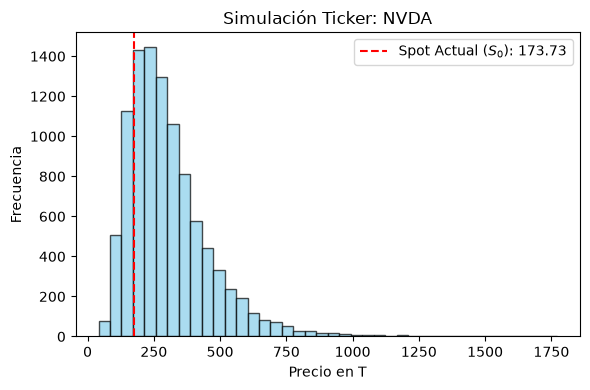

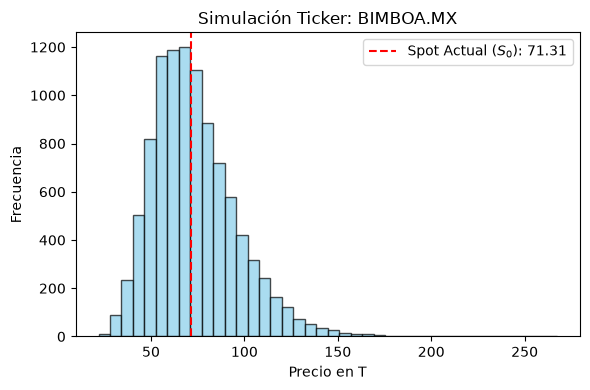

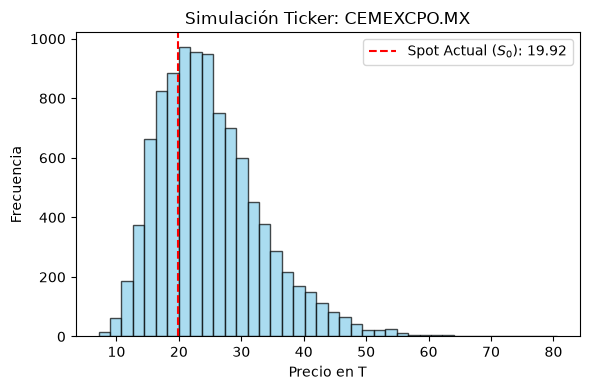

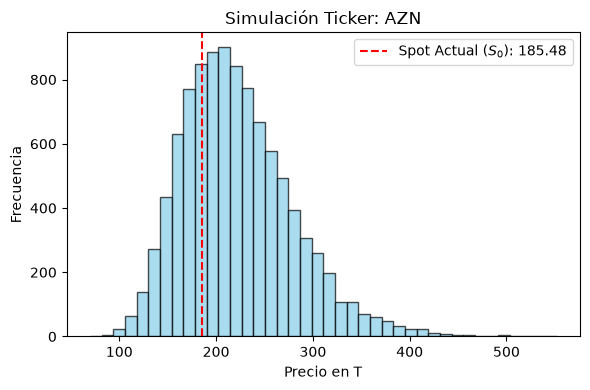

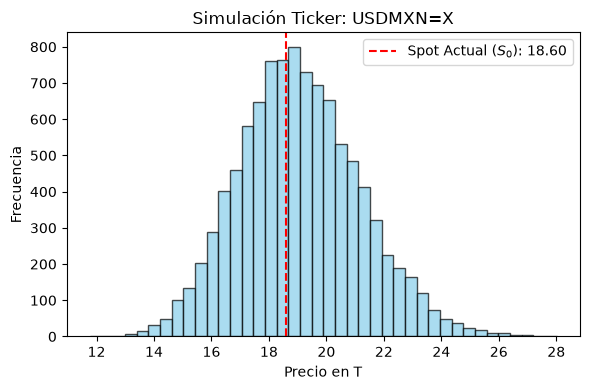

In [4]:
np.random.seed(42)
ST = {}  

for t_k in tickers:
    # Retornos logarítmicos históricos
    log_ret = np.log(data[t_k] / data[t_k].shift(1)).dropna()
    mu = log_ret.mean() * 252 + 0.5 * (log_ret.std() ** 2) * 252
    sigma = log_ret.std() * np.sqrt(252)

    # Simulación Monte Carlo 
    Z = np.random.normal(size=M)
    s_T = S0[t_k] * np.exp((mu - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)
    ST[t_k] = s_T

    plt.figure(figsize=(6, 4))
    plt.hist(s_T, bins=40, color="skyblue", edgecolor="black", alpha=0.7)
    plt.axvline(S0[t_k],color="red",linestyle="--", label=f"Spot Actual ($S_0$): {S0[t_k]:.2f}",)
    plt.title(f"Simulación Ticker: {t_k}")
    plt.xlabel("Precio en T")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.tight_layout()
    plt.show()

En esta parte se calcularon los retornos históricos de cada activo para anualizar su rendimiento y volatilidad, y  sus precios a un año asumiendo independencia entre ellos, graficando los resultados individuales frente al precio actual.

In [5]:
X_0 = S0["USDMXN=X"]
X_T = ST["USDMXN=X"]
VT_escenarios = {}

for nombre_esc, w in escenarios.items():
    # Asignación inicial en pesos por activo
    inv_mxn = w * V0
    N_i = np.zeros(4)

    for j in range(4):
        t_k = tickers[j]
        # MXN a USD 
        if monedas[j] == "USD":
            N_i[j] = (inv_mxn[j] / X_0) / S0[t_k]
        else:
            N_i[j] = inv_mxn[j] / S0[t_k]

    # Valor del portafolio para activos USD
    VALOR_T = np.zeros(M)
    for j in range(4):
        t_k = tickers[j]
        if monedas[j] == "USD":
            VALOR_T += N_i[j] * ST[t_k] * X_T
        else:
            VALOR_T += N_i[j] * ST[t_k]

    VT_escenarios[nombre_esc] = VALOR_T
    print(
        f"Escenario {nombre_esc} -> V_T Medio: ${VALOR_T.mean():,.2f} MXN"
    )


Escenario A -> V_T Medio: $178,942.73 MXN
Escenario B -> V_T Medio: $132,495.58 MXN
Escenario C -> V_T Medio: $125,199.10 MXN


Aqui se evaluan tres esquemas de inversión distintos partiendo de $100,000, calculando cuántas acciones compramos de cada activo (convirtiendo a dólares las que lo requieren) y proyectando el valor final del portafolio en un año para cada escenario.

# Simulación CORRELACIONADA (Ejercicio 1)

In [6]:
log_ret_full = np.log(data / data.shift(1)).dropna()
cov_matrix_full = log_ret_full.cov().values
mu_full = log_ret_full.mean().values * 252 + 0.5 * (log_ret_full.std().values ** 2) * 252
sigma_full = log_ret_full.std().values * np.sqrt(252)

L_full = np.linalg.cholesky(cov_matrix_full)
E_full = np.random.normal(0, 1, [len(tickers), M])
Z_corr_full = np.tensordot(L_full, E_full, axes=1)

mu_col_f = np.reshape(mu_full, (-1, 1))
sigma_col_f = np.reshape(sigma_full, (-1, 1))
S0_col_f = np.reshape(S0.values, (-1, 1))
ST_matriz_corr_full = S0_col_f * np.exp((mu_col_f - 0.5 * (sigma_col_f ** 2)) * T + sigma_col_f * np.sqrt(T) * Z_corr_full)

VT_corr_escenarios = {}
X_0_c = S0["USDMXN=X"]
X_T_c = ST_matriz_corr_full[tickers.index("USDMXN=X"), :]

Se aplica la descomposición de Cholesky sobre la matriz de covarianza real de todos los factores para generar variables aleatorias correlacionadas, simulando así de manera conjunta la evolución de los activos y del tipo de cambio considerando sus relaciones reales.

In [7]:
for nombre_esc, w in escenarios.items():
    inv_mxn = w * V0
    N_i = np.zeros(4)
    for j in range(4):
        t_k = tickers[j]
        idx_t = tickers.index(t_k)
        if monedas[j] == "USD":
            N_i[j] = (inv_mxn[j] / X_0_c) / S0[t_k]
        else:
            N_i[j] = inv_mxn[j] / S0[t_k]

    VALOR_T_corr = np.zeros(M)
    for j in range(4):
        t_k = tickers[j]
        idx_t = tickers.index(t_k)
        if monedas[j] == "USD":
            VALOR_T_corr += N_i[j] * ST_matriz_corr_full[idx_t, :] * X_T_c
        else:
            VALOR_T_corr += N_i[j] * ST_matriz_corr_full[idx_t, :]
    VT_corr_escenarios[nombre_esc] = VALOR_T_corr

Aqui se calcula el valor final de cada esquema de inversión usando los precios simulados con correlación, convirtiendo a pesos los activos en dólares usando el tipo de cambio proyectado de forma conjunta.

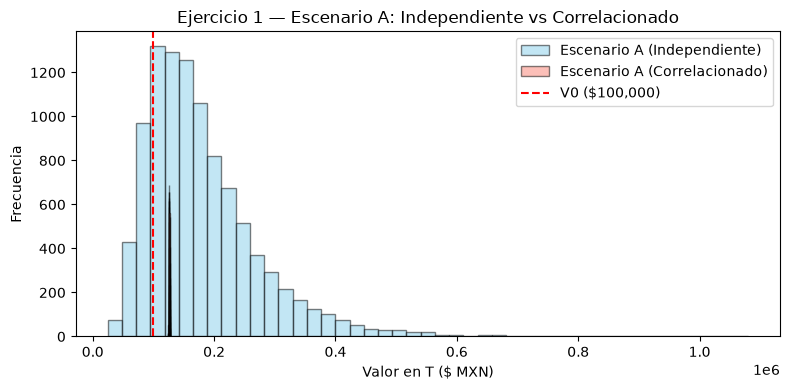

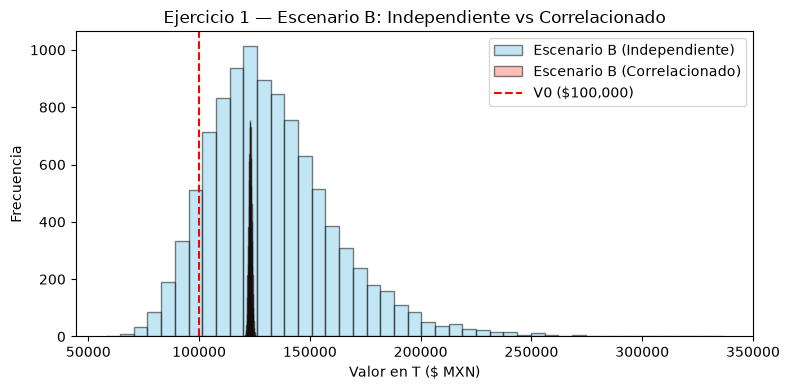

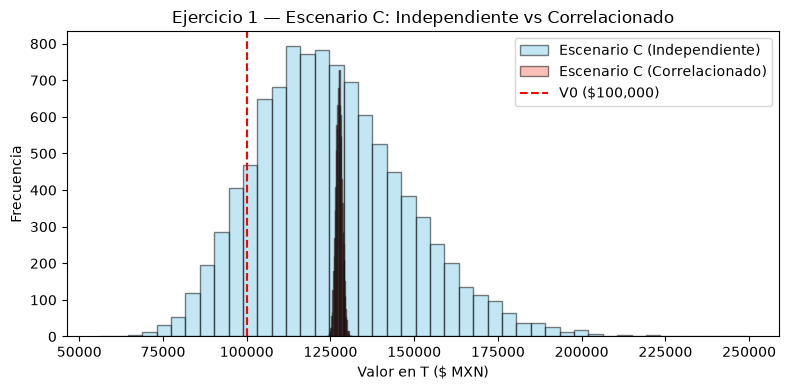

In [8]:
for esc in ["A", "B", "C"]:
    plt.figure(figsize=(8, 4))
    plt.hist(VT_escenarios[esc], bins=45, alpha=0.5, label=f"Escenario {esc} (Independiente)", color="skyblue", edgecolor="black")
    plt.hist(VT_corr_escenarios[esc], bins=45, alpha=0.5, label=f"Escenario {esc} (Correlacionado)", color="salmon", edgecolor="black")
    plt.axvline(V0, color="red", linestyle="--", label=f"V0 (${V0:,.0f})")
    plt.title(f"Ejercicio 1 — Escenario {esc}: Independiente vs Correlacionado")
    plt.xlabel("Valor en T ($ MXN)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.tight_layout()
    plt.show()

Las distribuciones del valor final de cada esquema de inversión bajo ambos supuestos (independiente vs. correlacionado), incluyendo una línea de referencia con el capital inicial para poder ver las diferencias en el riesgo y el rendimiento.

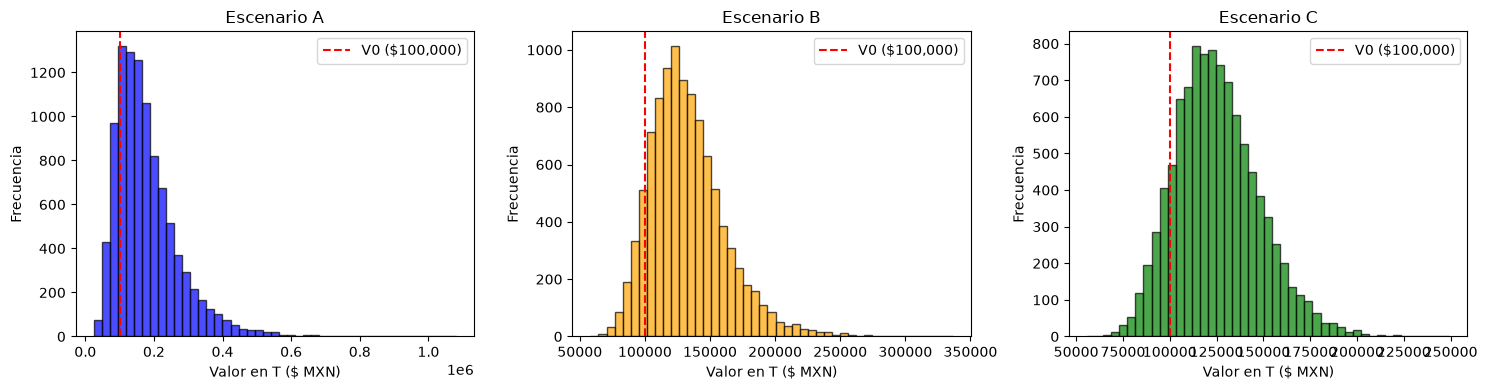

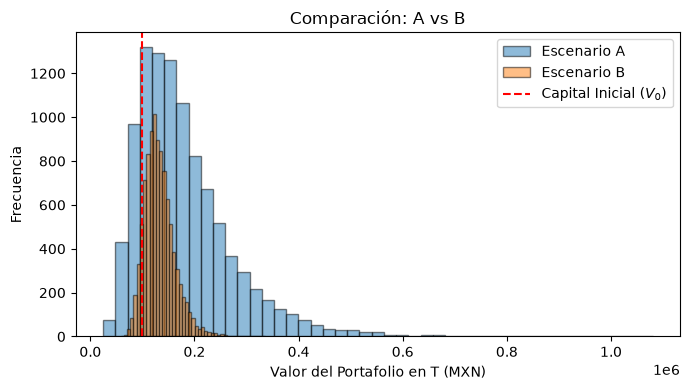

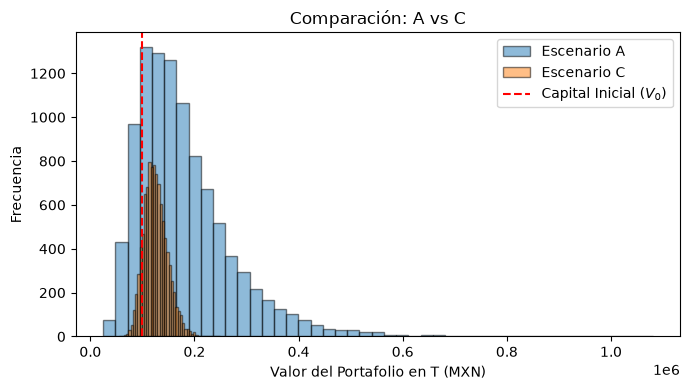

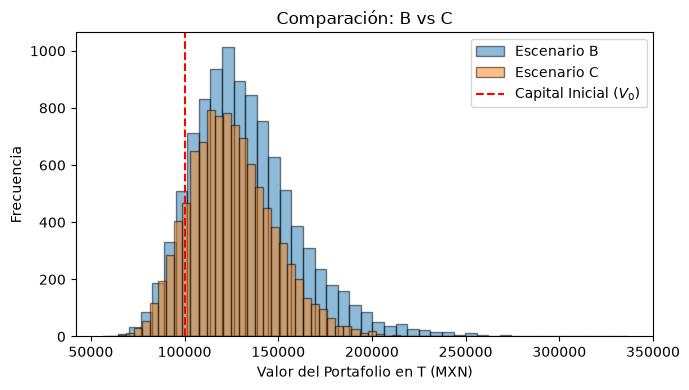

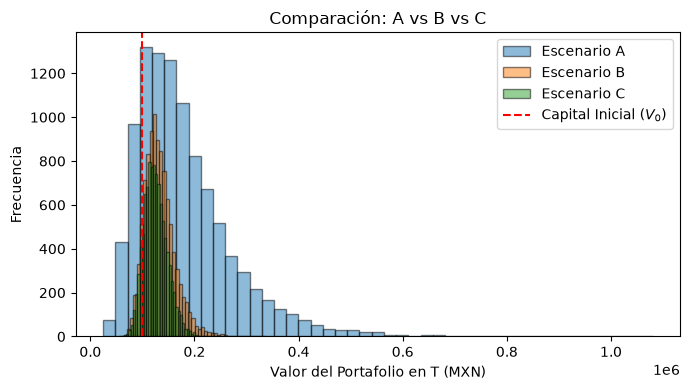

In [9]:
# Histogramas individuales de A, B y C
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
colores = ["blue", "orange", "green"]

for idx, (nombre_esc, vt_vals) in enumerate(VT_escenarios.items()):
    axes[idx].hist(
        vt_vals, bins=45, color=colores[idx], alpha=0.7, edgecolor="black"
    )
    axes[idx].axvline(
        V0, color="red", linestyle="--", label=f"V0 (${V0:,.0f})"
    )
    axes[idx].set_title(f"Escenario {nombre_esc}")
    axes[idx].set_xlabel("Valor en T ($ MXN)")
    axes[idx].set_ylabel("Frecuencia")
    axes[idx].legend()

plt.tight_layout()
plt.show()

# Comparaciones combinadas (A vs B, A vs C, B vs C, y A vs B vs C)
combinaciones = [("A", "B"), ("A", "C"), ("B", "C"), ("A", "B", "C")]

for comp in combinaciones:
    plt.figure(figsize=(7, 4))
    for esc in comp:
        plt.hist(
            VT_escenarios[esc],
            bins=45,
            alpha=0.5,
            label=f"Escenario {esc}",
            edgecolor="black",
        )
    plt.axvline(V0, color="red", linestyle="--", label="Capital Inicial ($V_0$)")
    plt.title(f"Comparación: {' vs '.join(comp)}")
    plt.xlabel("Valor del Portafolio en T (MXN)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.tight_layout()
    plt.show()

Histogramas individuales para cada uno de los tres escenarios y gráficos comparativos entre ellos para contrastar visualmente el comportamiento de las distintas distribuciones del portafolio frente al capital inicial.

# PARTE 2: EJERCICIO B (Portafolio Tecnológico: AAPL, MSFT, NVDA)

# Simulación Multiactivo

## Matriz de correlación

In [10]:
tickers = ["AAPL", "MSFT", "NVDA"]
data = yf.download(tickers, period="3y", progress=False)["Close"].dropna()

# Retornos logarítmicos 
log_returns = np.log(data / data.shift(1)).dropna()

# Matriz de correlación
corr_matrix = log_returns.corr()
cov_matrix = log_returns.cov()
print(corr_matrix.round(4).to_string())

Ticker    AAPL    MSFT    NVDA
Ticker                        
AAPL    1.0000  0.3411  0.2744
MSFT    0.3411  1.0000  0.4098
NVDA    0.2744  0.4098  1.0000


Se calcularon los retornos logarítmicos de los tickers ("AAPL", "MSFT", "NVDA") y obtenemos las matrices de correlación y covarianza para analizar el grado de relación lineal entre los activos.

In [11]:
mu_diario = log_returns.mean().values
sigma_diario = log_returns.std().values

# Drift y Volatilidad anualizados 
mu = mu_diario * 252 + 0.5 * (sigma_diario ** 2) * 252
sigma = sigma_diario * np.sqrt(252)


Se calcula la media y la desviación estándar de los retornos diarios para anualizarlas, añadiendo la corrección por volatilidad del Lema de Itô en el caso de la deriva.

In [12]:
M = 10000

L = np.linalg.cholesky(cov_matrix)

E = np.random.normal(0,1,[3,M])

Z = np.tensordot(L, E, axes=1)

print(Z)

[[ 0.01745304 -0.01956584  0.00974498 ...  0.00726913 -0.0155903
   0.01343242]
 [ 0.01837605 -0.0073258  -0.00371862 ... -0.02564281 -0.01462901
   0.00818017]
 [ 0.01054539  0.00033725  0.01988608 ... -0.02143442 -0.02240252
   0.03363927]]


Aqui se aplica la descomposición de Cholesky a la matriz de covarianza y la combinamos con variables aleatorias normales para generar choques estocásticos que muestren la correlación real entre las tres acciones tecnológicas en las 10,000 simulaciones.

In [13]:
S0 = np.array(data.iloc[-1])

# Redimensiona los parámetros a vectores columna (-1, 1) para operar en una sola línea
mu_col = np.reshape(mu, (-1, 1))
sigma_col = np.reshape(sigma, (-1, 1))
S0_col = np.reshape(S0, (-1, 1))

ST_matriz = S0_col * np.exp(
    (mu_col - 0.5 * (sigma_col ** 2)) * T
    + sigma_col * np.sqrt(T) * Z
)

Con los precios iniciales, se aplica la fórmula de proyección del movimiento browniano geométrico para calcular la matriz de precios finales simulados a un año, añadiendo la deriva, la volatilidad y los choques aleatorios correlacionados.

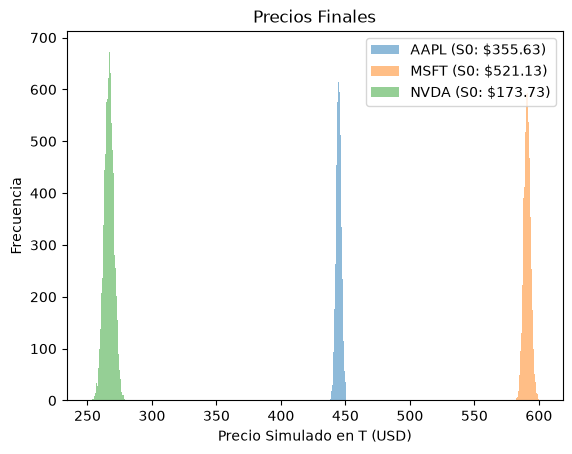

In [14]:
for i, ticker in enumerate(tickers):
  plt.hist(
      ST_matriz[i, :],
      bins=50,
      alpha=0.5,
      label=f"{ticker} (S0: ${S0[i]:.2f})",
  )

plt.title("Precios Finales")
plt.xlabel("Precio Simulado en T (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()


Aqui se muestran los precios finales de cada una de las acciones (Tickers).

## Escenarios (Portafolio)

In [15]:
escenarios = {
    "A": np.array([1.0, 0.0, 0.0]),
    "B": np.array([0.33, 0.33, 0.33]),
    "C": np.array([0.2, 0.2, 0.6]),
}

V0_total = 100000
S0 = np.array(data.iloc[-1])

In [16]:
mu_col = np.reshape(mu, (-1, 1))
sigma_col = np.reshape(sigma, (-1, 1))
S0_col = np.reshape(S0, (-1, 1))

# Matriz de precios finales por activo individual
ST_matriz = S0_col * np.exp((mu_col - 0.5 * (sigma_col ** 2)) * T + sigma_col * np.sqrt(T) * Z)

# Diccionario para guardar los resultados
resultados_netos = {}

Aqui se redimensionan los parámetros en vectores columna para calcular la matriz de precios finales simulados de cada activo y añadimos un diccionario para almacenar los resultados netos del portafolio.

In [17]:
for nombre, pesos in escenarios.items():
    ST_portafolio = 0
    for j, peso in enumerate(pesos):
        # Rentabilidad del activo (Precio Final / Precio Inicial)
        rentabilidad_activo = ST_matriz[j, :] / S0[j]
        # Valor final escalado
        ST_portafolio = ST_portafolio + (peso * rentabilidad_activo * V0_total)
        
    # Ganancia o pérdida neta 
    ganancia_neta = ST_portafolio - V0_total
    resultados_netos[nombre] = ganancia_neta

Se calcula el valor final del portafolio para cada escenario multiplicando los pesos asignados por la rentabilidad simulada de cada activo y el capital inicial, obteniendo la ganancia o pérdida neta en dólares.

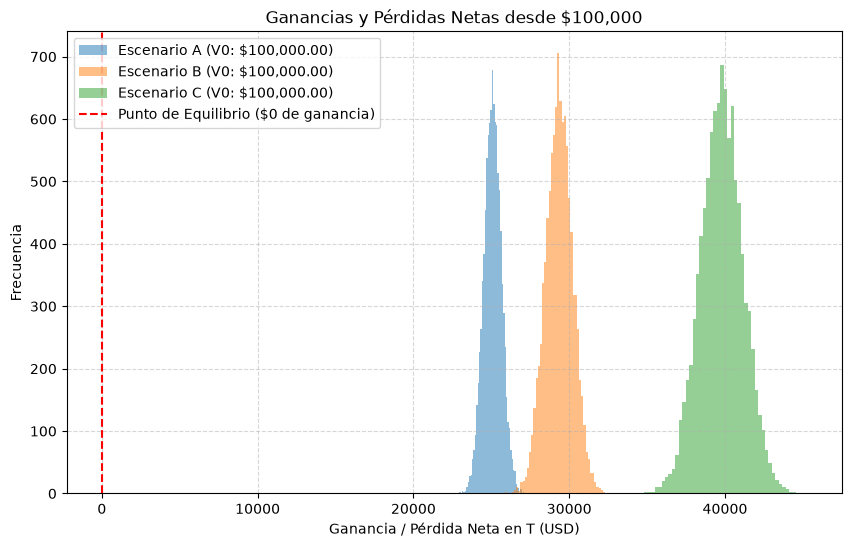

In [18]:
plt.figure(figsize=(10, 6))

for nombre, ganancia_neta in resultados_netos.items():
    plt.hist(
        ganancia_neta,
        bins=50,
        alpha=0.5,
        label=f"Escenario {nombre} (V0: ${V0_total:,.2f})"
    )

plt.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Punto de Equilibrio ($0 de ganancia)')
plt.title("Ganancias y Pérdidas Netas desde $100,000")
plt.xlabel("Ganancia / Pérdida Neta en T (USD)")
plt.ylabel("Frecuencia")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Ganancias y pérdidas netas de los tres escenarios tecnológicos a partir del capital inicial, añadiendo una línea vertical en cero para identificar claramente el punto de equilibrio entre rendimientos positivos y negativos.

# Gráficas comparativas por esquema 

In [ ]:
ST_matriz_ind = np.zeros((3, M))
for i in range(3):
    Z_ind = np.random.normal(0, 1, M)
    ST_matriz_ind[i, :] = S0[i] * np.exp((mu[i] - 0.5 * (sigma[i] ** 2)) * T + sigma[i] * np.sqrt(T) * Z_ind)

escenarios_2 = {
    "Esquema 1": np.array([1.0, 0.0, 0.0]),
    "Esquema 2": np.array([0.33, 0.33, 0.34]),
    "Esquema 3": np.array([0.2, 0.2, 0.6]),
}


Se simulan los precios de los activos bajo el supuesto de independencia utilizando variables aleatorias no correlacionadas y definimos los tres esquemas de inversión para evaluar su rendimiento.

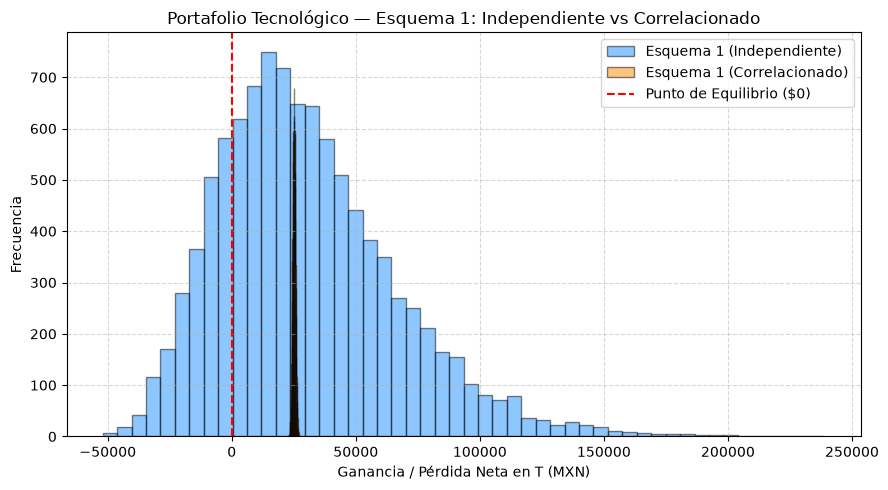

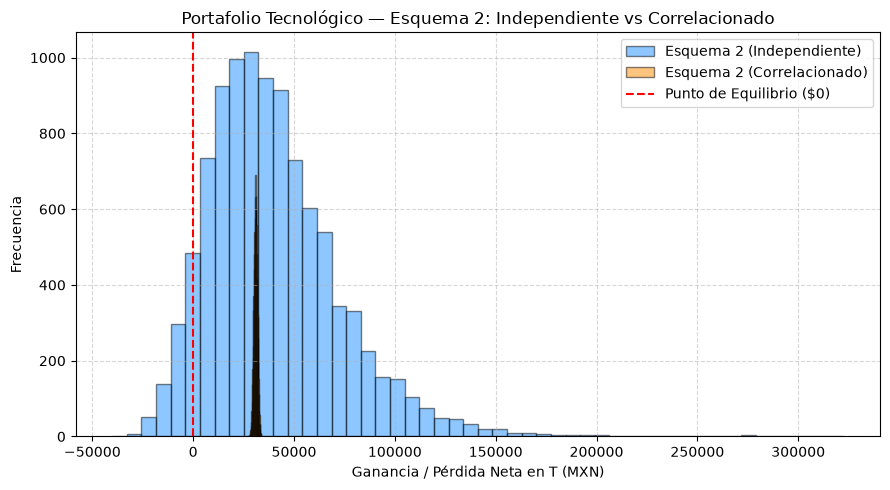

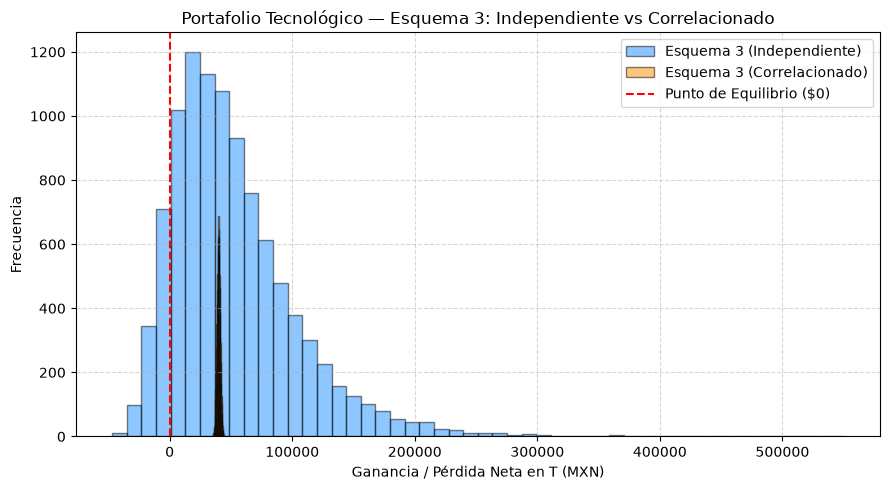

In [20]:
for nombre_esq, pesos in escenarios_2.items():
    ST_port_ind = 0
    ST_port_corr = 0
    for j, peso in enumerate(pesos):
        ST_port_ind += peso * (ST_matriz_ind[j, :] / S0[j]) * V0
        ST_port_corr += peso * (ST_matriz[j, :] / S0[j]) * V0
        
    ganancia_ind = ST_port_ind - V0
    ganancia_corr = ST_port_corr - V0

    plt.figure(figsize=(9, 5))
    plt.hist(ganancia_ind, bins=50, alpha=0.5, label=f"{nombre_esq} (Independiente)", color="dodgerblue", edgecolor="black")
    plt.hist(ganancia_corr, bins=50, alpha=0.5, label=f"{nombre_esq} (Correlacionado)", color="darkorange", edgecolor="black")
    plt.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Punto de Equilibrio ($0)")
    plt.title(f"Portafolio Tecnológico — {nombre_esq}: Independiente vs Correlacionado")
    plt.xlabel("Ganancia / Pérdida Neta en T (MXN)")
    plt.ylabel("Frecuencia")
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

Se comparan las ganancias y pérdidas netas de cada esquema de inversión del portafolio tecnológico bajo ambos modelos (independiente vs. correlacionado), con gráficas individuales para visualizar el impacto real de la correlación entre los activos frente al punto de equilibrio.

# Conclusión

Los resultados obtenidos al comparar los escenarios con supuestos de independencia frente a aquellos que tienen matrices de covarianza y descomposición de Cholesky muestran la importancia de modelar la dependencia entre activos financieros. El asumir que los componentes de un portafolio evolucionan de manera independiente hace que se subestime el riesgo de cola, ya que en los mercados, las correlaciones rara vez son nulas y los activos tienden a reaccionar de forma conjunta ante choques macroeconómicos o sectoriales.

En el caso del portafolio multidivisa, incluir la estructura de correlación conjunta entre los títulos internacionales y el tipo de cambio permite capturar con mayor precisión la dispersión del valor final en pesos mexicanos, evitando una falsa percepción de diversificación. 